# Análisis exploratorio de Berka

**Objetivo:** entender los datos antes de cargarlos y decidir qué reglas necesita el almacén. Las fechas están desplazadas 28 años, igual que en el banco simulado.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
from banco import berka

AZUL, GRIS, ROJO = "#12344D", "#9AA5B1", "#B42318"
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titleweight": "bold", "figure.dpi": 110})

trans = berka.leer("trans")
trans["fecha"] = pd.to_datetime(trans["date"].map(berka.fecha_negocio))
for columna in ("amount", "balance"):
    trans[columna] = pd.to_numeric(trans[columna])
trans["k_symbol"] = trans["k_symbol"].str.strip()
trans["operation"] = trans["operation"].str.strip()
loan = berka.leer("loan")
for columna in ("amount", "duration", "payments"):
    loan[columna] = pd.to_numeric(loan[columna])
loan["fecha"] = pd.to_datetime(loan["date"].map(berka.fecha_negocio))
print(f"{len(trans):,} movimientos | {trans['fecha'].min():%Y-%m-%d} a {trans['fecha'].max():%Y-%m-%d}")

1,056,320 movimientos | 2021-01-01 a 2026-12-31


## 1. Calidad de los movimientos

In [2]:
pd.DataFrame({
    "nulos o vacíos": trans.replace("", pd.NA).isna().sum(),
    "% del total": (trans.replace("", pd.NA).isna().mean() * 100).round(2),
})

,nulos o vacíos,% del total
trans_id,0,0.00
account_id,0,0.00
date,0,0.00
type,0,0.00
operation,183114,17.34
amount,0,0.00
balance,0,0.00
k_symbol,535314,50.68
bank,782812,74.11
account,760931,72.04


In [3]:
print("trans_id repetidos:", trans["trans_id"].duplicated().sum())
print("Montos cero o negativos:", (trans["amount"] <= 0).sum())
trans[trans["amount"] <= 0][["trans_id", "date", "type", "operation", "amount", "balance", "k_symbol"]]

trans_id repetidos: 0
Montos cero o negativos: 14


,trans_id,date,type,operation,amount,balance,k_symbol
83396,3455961,940831,VYDAJ,VYBER,0.0,72681.7,SANKC. UROK
108452,3451376,941130,VYDAJ,VYBER,0.0,-388.7,SANKC. UROK
132649,3452231,950131,VYDAJ,VYBER,0.0,113.1,SANKC. UROK
476849,3510214,970131,VYDAJ,VYBER,0.0,8488.2,SANKC. UROK
477624,3456605,970131,VYDAJ,VYBER,0.0,8502.9,SANKC. UROK
584641,3451866,970630,VYDAJ,VYBER,0.0,603.9,SANKC. UROK
729446,3449658,971231,VYDAJ,VYBER,0.0,197.0,SANKC. UROK
773057,3446795,980131,VYDAJ,VYBER,0.0,694.3,SANKC. UROK
793200,3456218,980228,PRIJEM,,0.0,1367.1,UROK
796237,3507085,980228,PRIJEM,,0.0,1367.1,UROK


### ¿Qué significa el tipo VYBER?

La guía solo documenta PRIJEM y VYDAJ. Se comprueba si el saldo baja como en un cargo.

In [4]:
orden = trans.sort_values(["account_id", "fecha", "trans_id"])
orden["saldo_previo"] = orden.groupby("account_id")["balance"].shift()
orden["cambio"] = (orden["balance"] - orden["saldo_previo"]).round(2)
orden["signo"] = (orden["amount"] * orden["type"].map({"PRIJEM": 1, "VYDAJ": -1, "VYBER": -1})).round(2)
validas = orden.dropna(subset=["saldo_previo"])
validas.groupby("type").apply(lambda g: pd.Series({
    "filas": len(g), "saldo_coincide_%": round((g["cambio"] == g["signo"]).mean() * 100, 1)}), include_groups=False)

,filas,saldo_coincide_%
type,,
PRIJEM,400583.0,63.1
VYBER,16666.0,79.7
VYDAJ,634571.0,73.6


### ¿Se puede usar trans_id para hallar el cierre del día?

En días con varios movimientos, el cierre real es el saldo del que no parte ningún otro movimiento. Se compara con el mayor trans_id y con la suma acumulada de abonos y cargos.

In [5]:
t = trans.assign(signo=trans["type"].map({"PRIJEM": 1, "VYDAJ": -1, "VYBER": -1}))
t["neto"] = (t["amount"] * t["signo"]).round(2)
t["saldo_antes"] = (t["balance"] - t["neto"]).round(2)
t["id"] = t["trans_id"].astype(int)
dia = t.groupby(["account_id", "date"], as_index=False).agg(neto=("neto", "sum"), n=("neto", "size")).sort_values(["account_id", "date"])
dia["acumulado"] = dia.groupby("account_id")["neto"].cumsum().round(2)

def cierre(grupo):
    saldos = list(grupo["balance"].round(2))
    for valor in grupo["saldo_antes"]:
        if valor in saldos:
            saldos.remove(valor)
    return saldos[0] if len(saldos) == 1 else float("nan")

varios = t.merge(dia[dia.n > 1][["account_id", "date"]], on=["account_id", "date"])
reales = varios.groupby(["account_id", "date"]).apply(cierre, include_groups=False).rename("cierre").reset_index().dropna()
mayor_id = varios.sort_values("id").groupby(["account_id", "date"]).tail(1)[["account_id", "date", "balance"]]
cruce = reales.merge(mayor_id, on=["account_id", "date"]).merge(dia, on=["account_id", "date"])
print(f"Mayor trans_id acierta el cierre: {((cruce['balance'] - cruce['cierre']).abs() < 0.015).mean():.1%}")
error = (cruce["acumulado"] - cruce["cierre"]).abs()
print(f"Acumulado: error medio {error.mean():.2f} CZK | percentil 99 {error.quantile(.99):.2f} | máximo {error.max():.2f}")

Mayor trans_id acierta el cierre: 21.1%
Acumulado: error medio 0.18 CZK | percentil 99 0.90 | máximo 2.80


## 2. Actividad en el tiempo

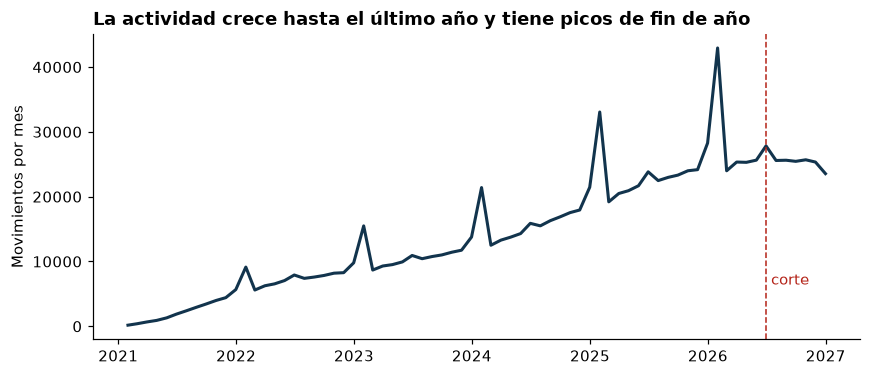

            movimientos
fecha                  
2026-06-30        27833
2026-07-31        25582
2026-08-31        25622
2026-09-30        25450
2026-10-31        25689
2026-11-30        25341
2026-12-31        23553


In [6]:
mensual = trans.set_index("fecha").resample("ME").agg(movimientos=("amount", "size"))
fig, ax = plt.subplots()
ax.plot(mensual.index, mensual["movimientos"], color=AZUL, lw=2)
ax.axvline(pd.Timestamp("2026-06-30"), color=ROJO, ls="--", lw=1)
ax.text(pd.Timestamp("2026-06-30"), mensual["movimientos"].max() * 0.15, " corte", color=ROJO)
ax.set_title("La actividad crece hasta el último año y tiene picos de fin de año")
ax.set_ylabel("Movimientos por mes"); plt.show()
print(mensual.tail(7))

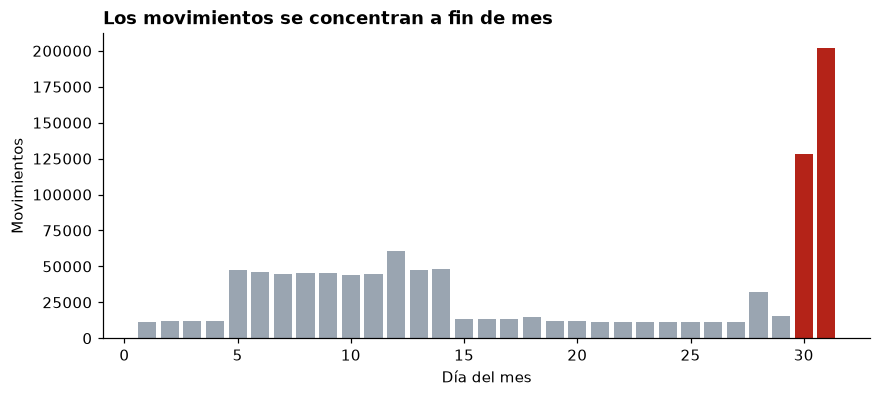

Parte de los movimientos en días 30 y 31: 31.3%


In [7]:
por_dia = trans.groupby(trans["fecha"].dt.day).size()
fig, ax = plt.subplots()
ax.bar(por_dia.index, por_dia.values, color=[ROJO if d >= 30 else GRIS for d in por_dia.index])
ax.set_title("Los movimientos se concentran a fin de mes"); ax.set_xlabel("Día del mes"); ax.set_ylabel("Movimientos"); plt.show()
print("Parte de los movimientos en días 30 y 31:", f"{por_dia[por_dia.index >= 30].sum() / por_dia.sum():.1%}")

## 3. Categorías y montos

In [8]:
resumen = trans.assign(categoria=trans["k_symbol"].replace("", "(vacío)")).groupby(["type", "categoria"])["amount"].agg(["size", "sum", "median"])
resumen.rename(columns={"size": "filas", "sum": "total", "median": "mediana"}).round(0).sort_values("total", ascending=False)

filas         total  mediana
type   categoria                                 
PRIJEM (vacío)      191631  3.032530e+09  13200.0
VYDAJ  (vacío)      327017  2.241059e+09   3200.0
       SIPO         118065  4.985064e+08   3369.0
VYBER  (vacío)       16666  2.086038e+08  12103.0
PRIJEM DUCHOD        30338  1.674721e+08   5553.0
VYDAJ  UVER          13580  5.525230e+07   3874.0
PRIJEM UROK         183114  2.747069e+07    133.0
VYDAJ  POJISTNE      18500  2.417519e+07    629.0
       SLUZBY       155832  2.686418e+06     15.0
       SANKC. UROK    1577  3.766300e+04      9.0

In [9]:
vacias = trans[trans["k_symbol"] == ""]
vacias.groupby(["type", "operation"]).size().sort_values(ascending=False).rename("filas").to_frame()

,,filas
type,operation,
VYDAJ,VYBER,258009
PRIJEM,VKLAD,156743
VYDAJ,PREVOD NA UCET,60972
PRIJEM,PREVOD Z UCTU,34888
VYBER,VYBER,16666
VYDAJ,VYBER KARTOU,8036


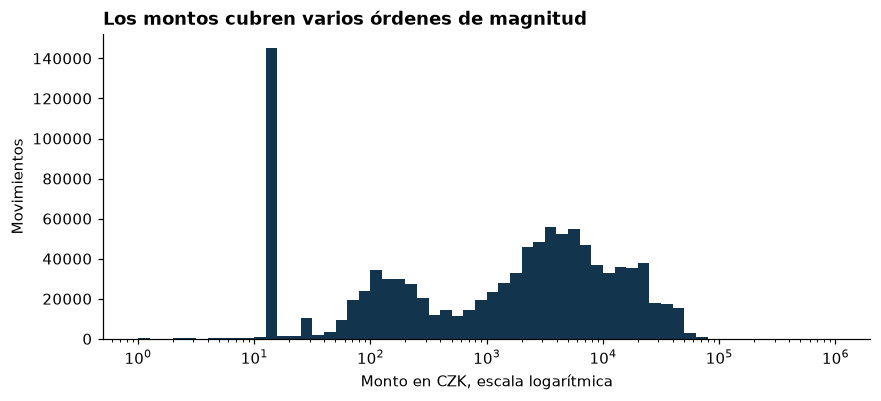

count    1056320.0
mean        5924.0
std         9523.0
min            0.0
50%         2100.0
90%        18400.0
99%        45455.0
max        87400.0
Name: amount, dtype: float64


In [10]:
fig, ax = plt.subplots()
ax.hist(trans["amount"].clip(lower=1), bins=pd.Series(range(0, 61)).map(lambda x: 10 ** (x / 10)).tolist(), color=AZUL)
ax.set_xscale("log"); ax.set_title("Los montos cubren varios órdenes de magnitud"); ax.set_xlabel("Monto en CZK, escala logarítmica"); ax.set_ylabel("Movimientos"); plt.show()
print(trans["amount"].describe(percentiles=[.5, .9, .99]).round(0))

## 4. Saldos negativos

In [11]:
negativos = trans[trans["balance"] < 0]
print(f"{len(negativos):,} movimientos en {negativos['account_id'].nunique()} cuentas | saldo mínimo {negativos['balance'].min():,.0f}")
con_prestamo = set(loan["account_id"])
print(f"Cuentas con saldo negativo que tienen préstamo: {negativos[negativos['account_id'].isin(con_prestamo)]['account_id'].nunique()}")
sancion = set(trans[trans["k_symbol"] == "SANKC. UROK"]["account_id"])
print(f"Cuentas con interés de sanción: {len(sancion)} | de ellas con saldo negativo: {len(sancion & set(negativos['account_id']))}")

2,999 movimientos en 288 cuentas | saldo mínimo -41,126
Cuentas con saldo negativo que tienen préstamo: 76
Cuentas con interés de sanción: 264 | de ellas con saldo negativo: 255


## 5. Préstamos

In [12]:
print("Cuota x plazo = monto:", ((loan["payments"] * loan["duration"] - loan["amount"]).abs() <= loan["duration"] + 1).sum(), "de", len(loan))
print("\nPlazo en meses:"); print(loan["duration"].value_counts().sort_index())
loan.groupby("status").agg(prestamos=("amount", "size"), monto_total=("amount", "sum"), monto_medio=("amount", "mean")).round(0)

Cuota x plazo = monto: 682 de 682

Plazo en meses:
duration
12    131
24    138
36    130
48    138
60    145
Name: count, dtype: int64


,prestamos,monto_total,monto_medio
status,,,
A,203,18603216,91641.0
B,31,4362348,140721.0
C,403,69078372,171410.0
D,45,11217804,249285.0


In [13]:
FIN = pd.Timestamp("2026-12-31")
uver = trans[trans["k_symbol"] == "UVER"].groupby("account_id").size().rename("pagos")
p = loan.merge(uver, left_on="account_id", right_index=True, how="left").fillna({"pagos": 0})
meses = (FIN.year - p["fecha"].dt.year) * 12 + (FIN.month - p["fecha"].dt.month)
p["esperadas"] = meses.clip(upper=p["duration"])
p["atrasadas"] = (p["esperadas"] - p["pagos"]).clip(lower=0)
p["en_mora"] = p["atrasadas"] > 1
p["problema"] = p["status"].isin(["B", "D"])
tabla = pd.crosstab(p["status"], p["en_mora"], margins=True); print(tabla)
print(f"Detecta {p[p.problema].en_mora.mean():.0%} de los problemáticos | falsas alertas: {(p.en_mora & ~p.problema).sum()} de {(~p.problema).sum()}")
pagos = trans[trans["k_symbol"] == "UVER"].merge(loan[["account_id", "payments"]], on="account_id")
print(f"Pagos UVER iguales a la cuota: {((pagos['amount'] - pagos['payments']).abs() < 0.01).mean():.1%}")
print((pagos["amount"] / pagos["payments"]).describe().round(3))

en_mora  False  True  All
status                   
A          201     2  203
B            6    25   31
C          402     1  403
D           16    29   45
All        625    57  682
Detecta 71% de los problemáticos | falsas alertas: 3 de 606
Pagos UVER iguales a la cuota: 54.5%
count    13580.000
mean         1.000
std          0.000
min          1.000
25%          1.000
50%          1.000
75%          1.000
max          1.002
dtype: float64


## 6. Margen: qué falta

In [14]:
montos = trans[trans["k_symbol"].isin(["UROK", "SLUZBY", "SANKC. UROK"])].groupby("k_symbol")["amount"].sum()
print(montos.round(0))
print(f"Comisiones y sanciones cubren {(montos['SLUZBY'] + montos['SANKC. UROK']) / montos['UROK']:.1%} de los intereses pagados")
print("Sin intereses de préstamos, el margen real observable sería negativo. Por eso se usa una tasa supuesta.")

k_symbol
SANKC. UROK       37663.0
SLUZBY          2686418.0
UROK           27470690.0
Name: amount, dtype: float64
Comisiones y sanciones cubren 9.9% de los intereses pagados
Sin intereses de préstamos, el margen real observable sería negativo. Por eso se usa una tasa supuesta.


## 7. Clientes y distritos

In [15]:
client = berka.leer("client"); district = berka.leer("district"); account = berka.leer("account")
print(account.groupby("district_id").size().describe().round(0))
por_region = account.merge(district, left_on="district_id", right_on="A1").groupby("A3").size().sort_values(ascending=False)
print(por_region)
print(district[district["A12"].eq("?") | district["A15"].eq("?")][["A1", "A2", "A12", "A15"]])
nac = client["birth_number"].map(berka.decodificar_nacimiento)
print("Nacidos entre", min(n[0] for n in nac), "y", max(n[0] for n in nac))

count     77.0
mean      58.0
std       61.0
min       32.0
25%       42.0
50%       48.0
75%       53.0
max      554.0
dtype: float64
A3
north Moravia      793
south Moravia      778
central Bohemia    574
Prague             554
east Bohemia       544
north Bohemia      457
west Bohemia       430
south Bohemia      370
dtype: int64
    A1       A2 A12 A15
68  69  Jesenik   ?   ?
Nacidos entre 1911-08-20 y 1987-09-27
